In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
# from statsmodels.stats.multitest import multipletests
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import r2_score 

In [2]:
df_prev = pd.read_csv('all_results_old_and_new.csv')
df_prev.shape

(754, 29)

In [3]:
df_babylm_10m = df_prev[df_prev.exp_info.str.startswith('babylm') & df_prev.encoding_setting.str.contains('default') & df_prev.response_setting.str.contains('default')]
df_babylm_10m

,exp_info,fromboyhoodtofatherhood_r2_mean,fromboyhoodtofatherhood_r_mean,mean_SPE_mean,mean_SPE_std,mean_cc_max_mean,mean_cc_max_std,mean_cc_norm_mean,mean_cc_norm_std,mean_corrs_unnorm_mean,...,S1_score_paths,S2_score_paths,S3_score_paths,stimulus_setting,encoding_setting,response_setting,name_setting,task,format_name_name,stimulus_setting_2
746,babylm-babyllama-10m-2024_9-default-default---...,0.004849,0.004849,0.190996,0.147713,0.412097,0.035575,0.064004,0.021591,0.029040,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_9,default,default,default_name,babylm-babyllama-10m-2024_9-default-default,default_name,NaN
747,babylm-babyllama-10m-2024_13-default-default--...,0.004636,0.004636,0.115086,0.091347,0.412097,0.035575,0.065040,0.021921,0.032601,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_13,default,default,default_name,babylm-babyllama-10m-2024_13-default-default,default_name,NaN
748,babylm-babyllama-10m-2024_5-default-default---...,0.004130,0.004130,0.099950,0.079927,0.412097,0.035575,0.065829,0.020818,0.029266,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_5,default,default,default_name,babylm-babyllama-10m-2024_5-default-default,default_name,NaN
749,babylm-babyllama-10m-2024_7-default-default---...,0.004634,0.004634,0.050352,0.068984,0.412097,0.035575,0.060749,0.021491,0.027359,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_7,default,default,default_name,babylm-babyllama-10m-2024_7-default-default,default_name,NaN
750,babylm-babyllama-10m-2024_3-default-default---...,0.004351,0.004351,0.246869,0.186113,0.412097,0.035575,0.066901,0.018528,0.029503,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_3,default,default,default_name,babylm-babyllama-10m-2024_3-default-default,default_name,NaN
751,babylm-babyllama-10m-2024_1-default-default---...,0.004513,0.004513,0.062822,0.068720,0.412097,0.035575,0.094398,0.015350,0.038659,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_1,default,default,default_name,babylm-babyllama-10m-2024_1-default-default,default_name,NaN
752,babylm-babyllama-10m-2024_11-default-default--...,0.004974,0.004974,0.102182,0.110581,0.412097,0.035575,0.063872,0.019358,0.031269,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_11,default,default,default_name,babylm-babyllama-10m-2024_11-default-default,default_name,NaN
753,babylm-babyllama-10m-2024_15-default-default--...,0.004135,0.004135,0.114826,0.073464,0.412097,0.035575,0.048475,0.016459,0.026029,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_15,default,default,default_name,babylm-babyllama-10m-2024_15-default-default,default_name,NaN


In [4]:
df_llama = df_prev[df_prev.exp_info.str.startswith('LLAMA') & df_prev.encoding_setting.str.contains('default') & df_prev.response_setting.str.contains('default')]
df_llama

,exp_info,fromboyhoodtofatherhood_r2_mean,fromboyhoodtofatherhood_r_mean,mean_SPE_mean,mean_SPE_std,mean_cc_max_mean,mean_cc_max_std,mean_cc_norm_mean,mean_cc_norm_std,mean_corrs_unnorm_mean,...,S1_score_paths,S2_score_paths,S3_score_paths,stimulus_setting,encoding_setting,response_setting,name_setting,task,format_name_name,stimulus_setting_2
1,LLAMA7B_4-default-default---default,0.029558,0.029558,-5.271338,0.769489,0.412097,0.035575,0.229077,0.032268,0.114437,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA7B_4,default,default,default,LLAMA7B_4-default-default,default,NaN
6,LLAMA13B_6-default-default---default,0.037238,0.037238,4.068749,27.457902,0.412097,0.035575,0.264826,0.031807,0.129592,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA13B_6,default,default,default,LLAMA13B_6-default-default,default,NaN
23,LLAMA65B_44-default-default---default,0.039034,0.039034,-14.104608,90.725952,0.412097,0.035575,0.263554,0.034156,0.132432,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA65B_44,default,default,default,LLAMA65B_44-default-default,default,NaN
30,LLAMA13B_16-default-default---default,0.041520,0.041520,-26.331943,19.828901,0.412097,0.035575,0.280632,0.031813,0.137670,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA13B_16,default,default,default,LLAMA13B_16-default-default,default,NaN
32,LLAMA65B_36-default-default---default,0.042558,0.042558,15.210569,55.476220,0.412097,0.035575,0.284238,0.032888,0.139668,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA65B_36,default,default,default,LLAMA65B_36-default-default,default,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
707,LLAMA38B_8-default-default---default,0.042430,0.042430,-6.871498,6.057030,0.412097,0.035575,0.290501,0.029093,0.140380,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA38B_8,default,default,default,LLAMA38B_8-default-default,default,NaN
713,LLAMA13B_18-default-default---default,0.041859,0.041859,-29.587234,16.218666,0.412097,0.035575,0.276359,0.033140,0.136176,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA13B_18,default,default,default,LLAMA13B_18-default-default,default,NaN
733,LLAMA30B_30-default-default---default,0.041198,0.041198,-112.658489,32.291762,0.412097,0.035575,0.279321,0.036855,0.137694,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA30B_30,default,default,default,LLAMA30B_30-default-default,default,NaN
734,LLAMA38B_4-default-default---default,0.034514,0.034514,-4.805651,1.405347,0.412097,0.035575,0.256974,0.028594,0.125767,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA38B_4,default,default,default,LLAMA38B_4-default-default,default,NaN


In [5]:
df_curr = pd.read_csv('all_results_1111.csv')
#df_curr

In [6]:
df_curr_wo_llama = df_curr[~df_curr.exp_info.str.startswith('llama')]
df_curr_wo_llama = df_curr_wo_llama[~df_curr_wo_llama.exp_info.str.startswith('babyllama-10m')]
df_curr_wo_llama

,exp_info,fromboyhoodtofatherhood_r2_mean,fromboyhoodtofatherhood_r_mean,mean_SPE_mean,mean_SPE_std,mean_cc_max_mean,mean_cc_max_std,mean_cc_norm_mean,mean_cc_norm_std,mean_corrs_unnorm_mean,...,wheretheressmoke_r_mean,S1_score_paths,S2_score_paths,S3_score_paths,stimulus_setting,encoding_setting,response_setting,name_setting,task,format_name_name
6,opt-125m-strict-2023_8-default-default---defau...,0.004460,0.004460,0.060749,0.043070,0.412097,0.035575,0.056908,0.020179,0.027644,...,0.005337,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/opt-125m-strict-2023_8,default,default,default_name,babylm/opt-125m-strict-2023_8-default-default,default_name
7,opt-125m-strict-small-2023_11-default-default-...,0.004631,0.004631,0.127617,0.120454,0.412097,0.035575,0.034419,0.020598,0.020168,...,0.004364,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/opt-125m-strict-small-2023_11,default,default,default_name,babylm/opt-125m-strict-small-2023_11-default-d...,default_name
9,babyllama-100m-2024_12-default-default---defau...,0.004649,0.004649,0.249299,0.254216,0.412097,0.035575,0.053267,0.016063,0.026477,...,0.005016,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/babyllama-100m-2024_12,default,default,default_name,babylm/babyllama-100m-2024_12-default-default,default_name
10,babyllama-100m-2024_15-default-default---defau...,0.004623,0.004623,0.108578,0.097196,0.412097,0.035575,0.047663,0.019045,0.024492,...,0.004741,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/babyllama-100m-2024_15,default,default,default_name,babylm/babyllama-100m-2024_15-default-default,default_name
11,opt-125m-strict-2023_11-default-default---defa...,0.004254,0.004254,0.054337,0.043851,0.412097,0.035575,0.047996,0.019693,0.025025,...,0.005132,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/opt-125m-strict-2023_11,default,default,default_name,babylm/opt-125m-strict-2023_11-default-default,default_name
12,babyllama-100m-2024_0-default-default---defaul...,0.004547,0.004547,0.059149,0.042614,0.412097,0.035575,0.064165,0.018018,0.029903,...,0.005615,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/babyllama-100m-2024_0,default,default,default_name,babylm/babyllama-100m-2024_0-default-default,default_name
13,opt-125m-strict-2023_0-default-default---defau...,0.004511,0.004511,-0.147299,0.135777,0.412097,0.035575,0.059995,0.019031,0.027465,...,0.004992,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/opt-125m-strict-2023_0,default,default,default_name,babylm/opt-125m-strict-2023_0-default-default,default_name
14,opt-125m-strict-small-2023_8-default-default--...,0.004476,0.004476,0.112237,0.120549,0.412097,0.035575,0.034972,0.023173,0.020099,...,0.004367,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/opt-125m-strict-small-2023_8,default,default,default_name,babylm/opt-125m-strict-small-2023_8-default-de...,default_name
15,babyllama-100m-2024_8-default-default---defaul...,0.004738,0.004738,0.239469,0.205010,0.412097,0.035575,0.059663,0.011659,0.028621,...,0.005238,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,/scratch/connectome/ahhyun724/NeuroBabyLM/data...,babylm/babylla

In [7]:
df_all = pd.concat([df_llama, df_curr_wo_llama, df_babylm_10m], ignore_index=True) #107+23+7 = 138
df_all

,exp_info,fromboyhoodtofatherhood_r2_mean,fromboyhoodtofatherhood_r_mean,mean_SPE_mean,mean_SPE_std,mean_cc_max_mean,mean_cc_max_std,mean_cc_norm_mean,mean_cc_norm_std,mean_corrs_unnorm_mean,...,S1_score_paths,S2_score_paths,S3_score_paths,stimulus_setting,encoding_setting,response_setting,name_setting,task,format_name_name,stimulus_setting_2
0,LLAMA7B_4-default-default---default,0.029558,0.029558,-5.271338,0.769489,0.412097,0.035575,0.229077,0.032268,0.114437,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA7B_4,default,default,default,LLAMA7B_4-default-default,default,NaN
1,LLAMA13B_6-default-default---default,0.037238,0.037238,4.068749,27.457902,0.412097,0.035575,0.264826,0.031807,0.129592,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA13B_6,default,default,default,LLAMA13B_6-default-default,default,NaN
2,LLAMA65B_44-default-default---default,0.039034,0.039034,-14.104608,90.725952,0.412097,0.035575,0.263554,0.034156,0.132432,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA65B_44,default,default,default,LLAMA65B_44-default-default,default,NaN
3,LLAMA13B_16-default-default---default,0.041520,0.041520,-26.331943,19.828901,0.412097,0.035575,0.280632,0.031813,0.137670,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA13B_16,default,default,default,LLAMA13B_16-default-default,default,NaN
4,LLAMA65B_36-default-default---default,0.042558,0.042558,15.210569,55.476220,0.412097,0.035575,0.284238,0.032888,0.139668,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA65B_36,default,default,default,LLAMA65B_36-default-default,default,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,babylm-babyllama-10m-2024_7-default-default---...,0.004634,0.004634,0.050352,0.068984,0.412097,0.035575,0.060749,0.021491,0.027359,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_7,default,default,default_name,babylm-babyllama-10m-2024_7-default-default,default_name,NaN
136,babylm-babyllama-10m-2024_3-default-default---...,0.004351,0.004351,0.246869,0.186113,0.412097,0.035575,0.066901,0.018528,0.029503,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_3,default,default,default_name,babylm-babyllama-10m-2024_3-default-default,default_name,NaN
137,babylm-babyllama-10m-2024_1-default-default---...,0.004513,0.004513,0.062822,0.068720,0.412097,0.035575,0.094398,0.015350,0.038659,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_1,default,default,default_name,babylm-babyllama-10m-2024_1-default-default,default_name,NaN
138,babylm-babyllama-10m-2024_11-default-default--...,0.004974,0.004974,0.102182,0.110581,0.412097,0.035575,0.063872,0.019358,0.031269,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_11,default,default,default_name,babylm-babyllama-10m-2024_11-default-default,default_name,NaN


In [8]:
df_all.exp_info.str.startswith('babyllama-100m').sum()

5

In [9]:
df_all[df_all.stimulus_setting.str.startswith('babylm-babyllama-10m')] 


,exp_info,fromboyhoodtofatherhood_r2_mean,fromboyhoodtofatherhood_r_mean,mean_SPE_mean,mean_SPE_std,mean_cc_max_mean,mean_cc_max_std,mean_cc_norm_mean,mean_cc_norm_std,mean_corrs_unnorm_mean,...,S1_score_paths,S2_score_paths,S3_score_paths,stimulus_setting,encoding_setting,response_setting,name_setting,task,format_name_name,stimulus_setting_2
132,babylm-babyllama-10m-2024_9-default-default---...,0.004849,0.004849,0.190996,0.147713,0.412097,0.035575,0.064004,0.021591,0.029040,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_9,default,default,default_name,babylm-babyllama-10m-2024_9-default-default,default_name,NaN
133,babylm-babyllama-10m-2024_13-default-default--...,0.004636,0.004636,0.115086,0.091347,0.412097,0.035575,0.065040,0.021921,0.032601,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_13,default,default,default_name,babylm-babyllama-10m-2024_13-default-default,default_name,NaN
134,babylm-babyllama-10m-2024_5-default-default---...,0.004130,0.004130,0.099950,0.079927,0.412097,0.035575,0.065829,0.020818,0.029266,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_5,default,default,default_name,babylm-babyllama-10m-2024_5-default-default,default_name,NaN
135,babylm-babyllama-10m-2024_7-default-default---...,0.004634,0.004634,0.050352,0.068984,0.412097,0.035575,0.060749,0.021491,0.027359,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_7,default,default,default_name,babylm-babyllama-10m-2024_7-default-default,default_name,NaN
136,babylm-babyllama-10m-2024_3-default-default---...,0.004351,0.004351,0.246869,0.186113,0.412097,0.035575,0.066901,0.018528,0.029503,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_3,default,default,default_name,babylm-babyllama-10m-2024_3-default-default,default_name,NaN
137,babylm-babyllama-10m-2024_1-default-default---...,0.004513,0.004513,0.062822,0.068720,0.412097,0.035575,0.094398,0.015350,0.038659,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_1,default,default,default_name,babylm-babyllama-10m-2024_1-default-default,default_name,NaN
138,babylm-babyllama-10m-2024_11-default-default--...,0.004974,0.004974,0.102182,0.110581,0.412097,0.035575,0.063872,0.019358,0.031269,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_11,default,default,default_name,babylm-babyllama-10m-2024_11-default-default,default_name,NaN
139,babylm-babyllama-10m-2024_15-default-default--...,0.004135,0.004135,0.114826,0.073464,0.412097,0.035575,0.048475,0.016459,0.026029,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_15,default,default,default_name,babylm-babyllama-10m-2024_15-default-default,default_name,NaN


In [10]:
df_all.to_csv('all_results_combined_1111.csv')

In [11]:
#EXCLUDE pythia-70m for now
#df_all = df_all[~df_all.exp_info.str.startswith('pythia-70m')]
df_all

,exp_info,fromboyhoodtofatherhood_r2_mean,fromboyhoodtofatherhood_r_mean,mean_SPE_mean,mean_SPE_std,mean_cc_max_mean,mean_cc_max_std,mean_cc_norm_mean,mean_cc_norm_std,mean_corrs_unnorm_mean,...,S1_score_paths,S2_score_paths,S3_score_paths,stimulus_setting,encoding_setting,response_setting,name_setting,task,format_name_name,stimulus_setting_2
0,LLAMA7B_4-default-default---default,0.029558,0.029558,-5.271338,0.769489,0.412097,0.035575,0.229077,0.032268,0.114437,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA7B_4,default,default,default,LLAMA7B_4-default-default,default,NaN
1,LLAMA13B_6-default-default---default,0.037238,0.037238,4.068749,27.457902,0.412097,0.035575,0.264826,0.031807,0.129592,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA13B_6,default,default,default,LLAMA13B_6-default-default,default,NaN
2,LLAMA65B_44-default-default---default,0.039034,0.039034,-14.104608,90.725952,0.412097,0.035575,0.263554,0.034156,0.132432,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA65B_44,default,default,default,LLAMA65B_44-default-default,default,NaN
3,LLAMA13B_16-default-default---default,0.041520,0.041520,-26.331943,19.828901,0.412097,0.035575,0.280632,0.031813,0.137670,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA13B_16,default,default,default,LLAMA13B_16-default-default,default,NaN
4,LLAMA65B_36-default-default---default,0.042558,0.042558,15.210569,55.476220,0.412097,0.035575,0.284238,0.032888,0.139668,...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,/data/connectome/dyhan316/semantic_decoding_da...,LLAMA65B_36,default,default,default,LLAMA65B_36-default-default,default,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,babylm-babyllama-10m-2024_7-default-default---...,0.004634,0.004634,0.050352,0.068984,0.412097,0.035575,0.060749,0.021491,0.027359,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_7,default,default,default_name,babylm-babyllama-10m-2024_7-default-default,default_name,NaN
136,babylm-babyllama-10m-2024_3-default-default---...,0.004351,0.004351,0.246869,0.186113,0.412097,0.035575,0.066901,0.018528,0.029503,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_3,default,default,default_name,babylm-babyllama-10m-2024_3-default-default,default_name,NaN
137,babylm-babyllama-10m-2024_1-default-default---...,0.004513,0.004513,0.062822,0.068720,0.412097,0.035575,0.094398,0.015350,0.038659,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_1,default,default,default_name,babylm-babyllama-10m-2024_1-default-default,default_name,NaN
138,babylm-babyllama-10m-2024_11-default-default--...,0.004974,0.004974,0.102182,0.110581,0.412097,0.035575,0.063872,0.019358,0.031269,...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,/pscratch/sd/a/ahhyun/NeuroBabyLM/encresult_10...,babylm-babyllama-10m-2024_11,default,default,default_name,babylm-babyllama-10m-2024_11-default-default,default_name,NaN


## PLOT!

In [12]:

import pandas as pd
import re

# Load the data
#df = pd.read_csv('all_results_old_and_new.csv')

# Filter for default settings
#df_filtered = df[(df['encoding_setting'] == 'default') & (df['response_setting'] == 'default')]

df_filtered=df_all

# Function to extract layer number
def extract_layer(stimulus_setting):
    match = re.search(r'_(\d+)$', stimulus_setting)
    if match:
        return int(match.group(1))
    return None

# Function to extract model base name (without layer number)
def extract_model_base(stimulus_setting):
    # Split by underscore and check if last part is a number
    parts = stimulus_setting.split('_')
    if len(parts) >= 2 and parts[-1].isdigit():
        # Remove the last part (layer number) to get base model name
        base = '_'.join(parts[:-1])
        return base
    return stimulus_setting

# Add columns
df_filtered = df_filtered.copy()
df_filtered['model_base'] = df_filtered['stimulus_setting'].apply(extract_model_base)
df_filtered['layer'] = df_filtered['stimulus_setting'].apply(extract_layer)

# Remove rows where layer is None
df_filtered = df_filtered.dropna(subset=['layer'])

# Create NUM_LAYERS_DICT
NUM_LAYERS_DICT = {}

print("Extracting NUM_LAYERS_DICT from data:")
print("=" * 60)

for model_base in sorted(df_filtered['model_base'].unique()):
    model_data = df_filtered[df_filtered['model_base'] == model_base]
    max_layer = int(model_data['layer'].max())
    all_layers = sorted([int(x) for x in model_data['layer'].unique()])
    
    # The total number of layers is typically max_layer + 1
    # (since layer indexing often starts from 0)
    # But let's also check if there's a pattern
    
    # Check if layers start from 0 or 1
    min_layer = int(model_data['layer'].min())
    
    if min_layer == 0:
        # Layers indexed from 0, so total layers = max_layer + 1
        total_layers = max_layer + 1
    else:
        # Layers might be indexed from 1, or sampled differently
        total_layers = max_layer + 1
    
    NUM_LAYERS_DICT[model_base] = total_layers
    
    print(f"\n{model_base}:")
    print(f"  Layers tested: {all_layers}")
    print(f"  Min layer: {min_layer}, Max layer: {max_layer}")
    print(f"  Inferred total layers: {total_layers}")

NUM_LAYERS_DICT


Extracting NUM_LAYERS_DICT from data:

EleutherAI/pythia-14m:
  Layers tested: [0, 1, 2, 3, 4, 5]
  Min layer: 0, Max layer: 5
  Inferred total layers: 6

EleutherAI/pythia-70m:
  Layers tested: [0, 1, 2, 3, 4, 5]
  Min layer: 0, Max layer: 5
  Inferred total layers: 6

LLAMA13B:
  Layers tested: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38]
  Min layer: 0, Max layer: 38
  Inferred total layers: 39

LLAMA27Bhf:
  Layers tested: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 24, 26, 28, 30]
  Min layer: 0, Max layer: 30
  Inferred total layers: 31

LLAMA30B:
  Layers tested: [0, 3, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48, 51, 54, 57]
  Min layer: 0, Max layer: 57
  Inferred total layers: 58

LLAMA38B:
  Layers tested: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]
  Min layer: 0, Max layer: 30
  Inferred total layers: 31

LLAMA65B:
  Layers tested: [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 64, 68, 72, 76]
  Min layer: 0,

{'EleutherAI/pythia-14m': 6,
 'EleutherAI/pythia-70m': 6,
 'LLAMA13B': 39,
 'LLAMA27Bhf': 31,
 'LLAMA30B': 58,
 'LLAMA38B': 31,
 'LLAMA65B': 77,
 'LLAMA7B': 31,
 'babylm-babyllama-10m-2024': 16,
 'babylm/babyllama-100m-2024': 16,
 'babylm/opt-125m-strict-2023': 12,
 'babylm/opt-125m-strict-small-2023': 12}

In [13]:
max_layer_indices = df_filtered.groupby('model_base')['layer'].max()
NUM_LAYERS_DICT = (max_layer_indices + 1).to_dict()

print("Dynamically calculated total layers (N) for each model:")
print(NUM_LAYERS_DICT)

Dynamically calculated total layers (N) for each model:
{'EleutherAI/pythia-14m': 6, 'EleutherAI/pythia-70m': 6, 'LLAMA13B': 39, 'LLAMA27Bhf': 31, 'LLAMA30B': 58, 'LLAMA38B': 31, 'LLAMA65B': 77, 'LLAMA7B': 31, 'babylm-babyllama-10m-2024': 16, 'babylm/babyllama-100m-2024': 16, 'babylm/opt-125m-strict-2023': 12, 'babylm/opt-125m-strict-small-2023': 12}


In [16]:
from utils_perf_df import analyze_custom_settings_combinations, filter_sort_and_convert_to_numeric
from utils_plotter import plot_baseline_value
import matplotlib.pyplot as plt
import pandas as pd

all_results = df_all

columns_of_interest = [ 'mean_cc_norm_mean', 'mean_cc_norm_std', 'mean_r2_mean', 'mean_r2_std', 'stimulus_setting', 'stimulus_setting_2', 'encoding_setting', 'response_setting', 'format_name_name'] #, 'name_setting', 'task', 'format_name_name'] 'exp_info',

final_results = all_results[columns_of_interest]
final_results = final_results.reset_index(drop = True)
final_results = final_results[final_results['format_name_name'].str.contains('loss_criteria__MAE|default')]

settings_list = ['stimulus_setting', 'encoding_setting', 'response_setting', 'stimulus_setting_2']
results = analyze_custom_settings_combinations(final_results, settings_list)


In [17]:
results

{'stimulus_setting__encoding_setting': {('LLAMA30B_18',
   'default'):     mean_cc_norm_mean  mean_cc_norm_std  mean_r2_mean  mean_r2_std  \
  58           0.294887          0.030179      0.036746     0.012087   
  89           0.315729          0.037396      0.041056     0.012360   
  
     stimulus_setting                   stimulus_setting_2 encoding_setting  \
  58      LLAMA30B_18                                  NaN          default   
  89      LLAMA30B_18  whisper-large_final_default_default          default   
  
     response_setting format_name_name  
  58          default          default  
  89          default          default  ,
  ('LLAMA7B_12',
   'default'):     mean_cc_norm_mean  mean_cc_norm_std  mean_r2_mean  mean_r2_std  \
  17           0.291187          0.032249      0.036620      0.01230   
  90           0.313579          0.038392      0.041009      0.01263   
  
     stimulus_setting                   stimulus_setting_2 encoding_setting  \
  17       LLAMA7B_1

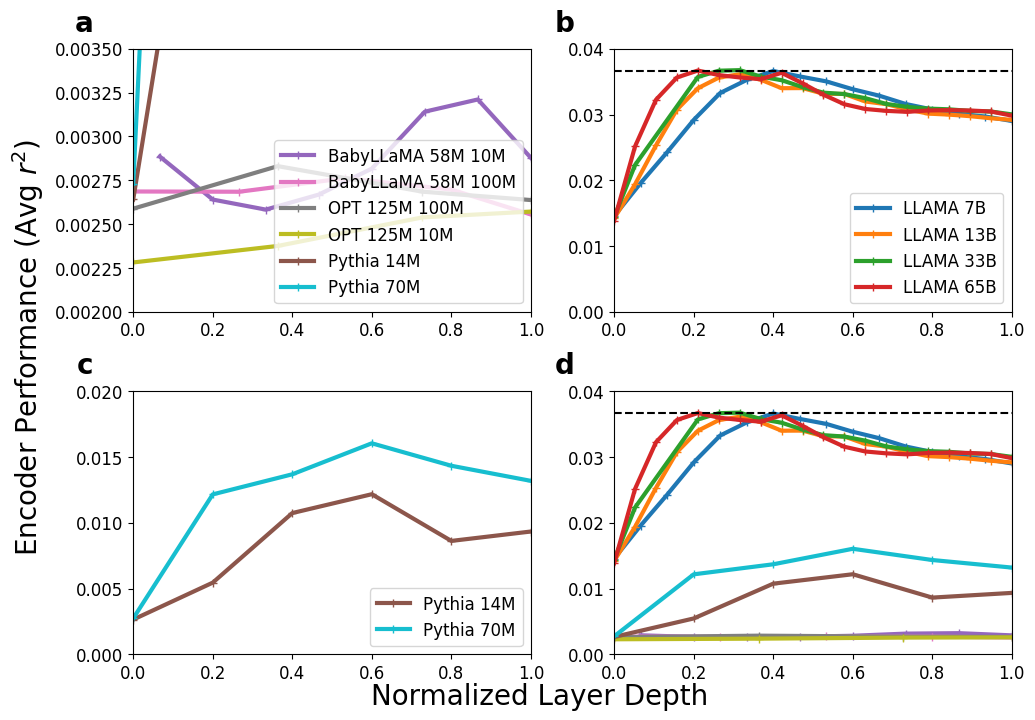

In [24]:
# --- Define the Model-to-Color Mapping (Place this near the model2name_dict) ---

model2name_dict = {
    "LLAMA7B": "LLAMA 7B",
    "LLAMA13B": "LLAMA 13B",
    "LLAMA30B": "LLAMA 33B",
    "LLAMA65B": "LLAMA 65B",
    "LLAMA27Bhf": "LLAMA-2 7B",
    "LLAMA38B": "LLAMA-3 8B",
    "babylm-babyllama-10m-2024": "BabyLLaMA 58M 10M",
    "babylm/babyllama-100m-2024": "BabyLLaMA 58M 100M",
    "EleutherAI/pythia-14m": "Pythia 14M",
    "EleutherAI/pythia-70m": "Pythia 70M",
    'babylm/opt-125m-strict-2023': "OPT 125M 100M",
    'babylm/opt-125m-strict-small-2023': "OPT 125M 10M"
}

MODEL_COLORS = {
    "LLAMA7B": "tab:blue",
    "LLAMA13B": "tab:orange",
    "LLAMA30B": "tab:green",    # For LLAMA 33B
    "LLAMA65B": "tab:red",
    "LLAMA27Bhf": "tab:orange", # For LLAMA-2 7B
    "LLAMA38B": "tab:green",    # For LLAMA-3 8B
    "babylm-babyllama-10m-2024": "tab:purple", 
    "babylm/babyllama-100m-2024": "tab:pink",
    "EleutherAI/pythia-14m": "tab:brown",
    "EleutherAI/pythia-70m": "tab:cyan",
    'babylm/opt-125m-strict-2023': "tab:gray",
    'babylm/opt-125m-strict-small-2023': "tab:olive"
}
# ---------------------------------------------------------------------------------

# # Define the criteria and x-axis
criteria = 'mean_r2_mean'
x_axis = 'stimulus_setting'


def extra_plot_settings(ax, title, xlim, ylim, criteria, xlabel="Normalized Layer Depth", ylabel="Encoder Performance (Avg $r^2$)", fontsize=16, loc = 'lower right' , include_legend=True, **kwargs):
    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.tick_params(axis='both', labelsize=fontsize)

    if include_legend:
        ax.legend(fontsize=fontsize, loc=loc)
    plot_baseline_value(criteria, ax_or_plt=ax, **kwargs)
    

# Function to plot data for given models (CORRECTED to use MODEL_COLORS)
def plot_models(ax, models, title, xlabel, ylabel, xlim, ylim, fontsize = 12, **kwargs):
    
    for model in models:
        # 🎯 Determine the base model key (e.g., 'LLAMA7B', not 'LLAMA7B_layer_2')
        model_key = model.split('_')[0]
        
        # 🎨 Get the color from the global map. Default to black if key is missing.
        color_to_use = MODEL_COLORS.get(model_key, 'black')
        
        df = results['encoding_setting__response_setting'][("default", "default")]
        # Use a raw string r'' for the regex pattern
        df = df[df['stimulus_setting'].str.contains(r'^' + model, na=False)]
        numerized_df = filter_sort_and_convert_to_numeric(df, {}, multimodal=False, sort_by=x_axis,
                                                          colunmns2convert=['stimulus_setting'])
        
        ax.plot(
            numerized_df[x_axis] / (NUM_LAYERS_DICT[model_key] - 1), 
            numerized_df[criteria], 
            label=model2name_dict[model_key], 
            marker='+', 
            linewidth=3,
            color=color_to_use # <--- KEY CHANGE: Use the specific model color
        )
    extra_plot_settings(ax, title, xlim, ylim, criteria, xlabel, ylabel, fontsize = fontsize, **kwargs)

# NOTE: You must ensure NUM_LAYERS_DICT uses these base keys: 'LLAMA7B', 'LLAMA13B', etc.
# If it currently uses 'LLAMA7Bhf', update the code to handle that split. 
# Based on the snippet, I've adjusted the code to use model.split('_')[0] for both color lookup and NUM_LAYERS_DICT lookup.

fig, axs = plt.subplots(2, 2, figsize=(10, 7))

# Plot LLAMA7B version variations in the first row
#plot_models(axs[0, 0], ["LLAMA7B", "LLAMA27Bhf", "LLAMA38B"], None, None, None, (0, 1), (0, 0.04))
plot_models(axs[0, 1], ["LLAMA7B", "LLAMA13B", "LLAMA30B", "LLAMA65B"], None, None, None, (0, 1), (0, 0.04))

# Plot BabyLM and all models comparison in the second row
plot_models(axs[0, 0], ["babylm-babyllama-10m-2024", "babylm/babyllama-100m-2024", "babylm/opt-125m-strict-2023", "babylm/opt-125m-strict-small-2023", "EleutherAI/pythia-14m", "EleutherAI/pythia-70m"], None, None, None, (0, 1), (0.002, 0.0035))

plot_models(axs[1, 0], ["EleutherAI/pythia-14m", "EleutherAI/pythia-70m"], None, None, None, (0, 1), (0, 0.02))

plot_models(axs[1, 1], ["LLAMA7B", "LLAMA13B", "LLAMA30B", "LLAMA65B", "babylm-babyllama-10m-2024", "babylm/babyllama-100m-2024", "babylm/opt-125m-strict-2023", "babylm/opt-125m-strict-small-2023", "EleutherAI/pythia-14m", "EleutherAI/pythia-70m"], None, None, None, (0, 1), (0, 0.04), include_legend=False)


# Plot Whisper version variations in the second row
#plot_models(axs[1, 0], ['whisper-tiny_(\\d+|\\w+)+_default_default', 'whisper-small_(\\d+|\\w+)_default_default', 'whisper-base_(\\d+|\\w+)_default_default','whisper-large_(\\d+|\\w+)+_default_default'], None, None, None, (0, 1), (0, 0.03), whisper=True)
#plot_models(axs[1, 1], ['whisper-large_(\\d+|\\w+)+_default_default', 'whisper-large-v2_(\\d+|\\w+)_default_default', 'whisper-large-v3_(\\d+|\\w+)_default_default'], None, None, None , (0, 1), (0, 0.03), whisper=True)

# Add labels (a, b, c, d) on top of each subplot
labels = ['a', 'b', 'c', 'd']
for i, ax in enumerate(axs.flat):
    ax.text(-0.1, 1.15, labels[i], transform=ax.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')


# Adjust layout
plt.tight_layout()
# fig.suptitle("Encoder Performance vs. Normalized Layer Depth", fontsize=25, y=1.10)
# Add common x-label and y-label
fig.text(0.5, -0.01, 'Normalized Layer Depth', ha='center', fontsize=20)
fig.text(-0.03, 0.5, 'Encoder Performance (Avg $r^2$)', va='center', rotation='vertical', fontsize=20)

plt.savefig('./FIGURES/scaling_figure.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# from utils_perf_df import analyze_custom_settings_combinations, filter_sort_and_convert_to_numeric
# from utils_plotter import plot_baseline_value # Assuming this is correctly imported
# import matplotlib.pyplot as plt
# import pandas as pd
# import numpy as np 

# # Assume NUM_LAYERS_DICT is defined somewhere, adding a placeholder for demonstration
# # You should ensure your actual NUM_LAYERS_DICT is defined before this line
# NUM_LAYERS_DICT = {
#     "LLAMA7B": 32,
#     "LLAMA13B": 40,
#     "LLAMA30B": 60,
#     "LLAMA65B": 80,
#     "LLAMA27Bhf": 32,
#     "LLAMA38B": 32,
#     "babylm-babyllama-10m-2024": 12 
# }


# all_results = pd.read_csv("./all_results_old_and_new.csv")

# columns_of_interest = [ 'mean_cc_norm_mean', 'mean_cc_norm_std', 'mean_r2_mean', 'mean_r2_std', 'stimulus_setting', 'stimulus_setting_2', 'encoding_setting', 'response_setting', 'format_name_name']

# final_results = all_results[columns_of_interest]
# final_results = final_results.reset_index(drop = True)
# final_results = final_results[final_results['format_name_name'].str.contains('loss_criteria__MAE|default')]

# settings_list = ['stimulus_setting', 'encoding_setting', 'response_setting', 'stimulus_setting_2']
# results = analyze_custom_settings_combinations(final_results, settings_list)



# # Define the model to name dictionary
# model2name_dict = {
#     "LLAMA7B": "LLAMA 7B",
#     "LLAMA13B": "LLAMA 13B",
#     "LLAMA30B": "LLAMA 33B",
#     "LLAMA65B": "LLAMA 65B",
#     "LLAMA27Bhf": "LLAMA-2 7B",
#     "LLAMA38B": "LLAMA-3 8B",
#     "babylm-babyllama-10m-2024": "BabyLLaMA 58M 10M"
# }

# # Define the criteria and x-axis
# criteria = 'mean_r2_mean'
# x_axis = 'stimulus_setting'

# # 1. MODIFIED: Function to apply extra plot settings (NO LEGEND/BASELINE PLOTTING HERE)
# def extra_plot_settings_main(ax, title, xlim, ylim, criteria, xlabel="Normalized Layer Depth", ylabel="Encoder Performance (Avg $r^2$)", fontsize=16, **kwargs):
#     # Only set labels if they are NOT None (allowing global fig.text to override)
#     if xlabel is not None:
#         ax.set_xlabel(xlabel, fontsize=fontsize)
#     if ylabel is not None:
#         ax.set_ylabel(ylabel, fontsize=fontsize)
    
#     ax.set_title(title, fontsize=fontsize)
#     ax.set_xlim(xlim)
#     ax.set_ylim(ylim)
#     ax.tick_params(axis='both', labelsize=fontsize)
#     # ax.legend(...) # Removed
#     # plot_baseline_value(...) # Removed


# # 2. MODIFIED: Function to plot data and return legend handles/labels
# def plot_models_and_return_legend(ax, models, title, xlabel, ylabel, xlim, ylim, fontsize = 12, loc = 'lower right', **kwargs):
#     for model in models:
#         df = results['encoding_setting__response_setting'][("default", "default")]
#         # Using a raw string r'' for the regex pattern
#         df = df[df['stimulus_setting'].str.contains(r'^' + model, na=False)]
#         numerized_df = filter_sort_and_convert_to_numeric(df, {}, multimodal=False, sort_by=x_axis,
#                                                           colunmns2convert=['stimulus_setting'])
#         ax.plot(numerized_df[x_axis] / (NUM_LAYERS_DICT[model.split('_')[0]] - 1), numerized_df[criteria], label=model2name_dict[model], marker='+', linewidth=3)
    
#     # Run extra settings for the main plot
#     # The default labels are used if xlabel/ylabel are None
#     extra_plot_settings_main(ax, title, xlim, ylim, criteria, xlabel, ylabel, fontsize = fontsize)
    
#     # Run the baseline plotting to ensure the line is on the main figure
#     plot_baseline_value(criteria, ax_or_plt=ax, **kwargs)

#     # Collect all handles/labels (models + baseline) for the external legend
#     all_handles, all_labels = ax.get_legend_handles_labels()
    
#     return all_handles, all_labels, loc


# # Create a 2x2 grid of subplots for the main figure
# fig, axs = plt.subplots(2, 2, figsize=(10, 7))

# # A list to store legend data for each subplot
# legend_data = [] # Stores: [(handles, labels, loc), ...]

# # --- START OF CORRECTED CALLS ---

# # Plot A: LLAMA 7B Generations
# handles_a, labels_a, loc_a = plot_models_and_return_legend(
#     axs[0, 0], 
#     ["LLAMA7B", "LLAMA27Bhf", "LLAMA38B"], 
#     title="(a) LLAMA 7B Generations", 
#     xlabel=None, 
#     ylabel=None, 
#     xlim=(0, 1), 
#     ylim=(0, 0.04)
# )
# legend_data.append((handles_a, labels_a, loc_a))

# # Plot B: LLAMA Parameter Scaling
# handles_b, labels_b, loc_b = plot_models_and_return_legend(
#     axs[0, 1], 
#     ["LLAMA7B", "LLAMA13B", "LLAMA30B", "LLAMA65B"], 
#     title="(b) LLAMA Parameter Scaling", 
#     xlabel=None, 
#     ylabel=None, 
#     xlim=(0, 1), 
#     ylim=(0, 0.04)
# )
# legend_data.append((handles_b, labels_b, loc_b))

# # Plot C: BabyLLaMA
# handles_c, labels_c, loc_c = plot_models_and_return_legend(
#     axs[1, 0], 
#     ["babylm-babyllama-10m-2024"], 
#     title="(c) BabyLLaMA", 
#     xlabel=None, 
#     ylabel=None, 
#     xlim=(0, 1), 
#     ylim=(0, 0.004)
# )
# legend_data.append((handles_c, labels_c, loc_c))

# # Plot D: All Models Comparison
# handles_d, labels_d, loc_d = plot_models_and_return_legend(
#     axs[1, 1], 
#     ["LLAMA7B", "LLAMA13B", "LLAMA30B", "LLAMA65B", "babylm-babyllama-10m-2024"], 
#     title="(d) All Models Comparison", 
#     xlabel=None, 
#     ylabel=None, 
#     xlim=(0, 1), 
#     ylim=(0, 0.04), 
#     loc ='center right'
# )
# legend_data.append((handles_d, labels_d, loc_d))

# # --- END OF CORRECTED CALLS ---

# # Adjust layout
# plt.tight_layout()
# # Add common x-label and y-label using fig.text
# fig.text(0.5, -0.01, 'Normalized Layer Depth', ha='center', fontsize=20)
# fig.text(-0.03, 0.5, 'Encoder Performance (Avg $r^2$)', va='center', rotation='vertical', fontsize=20)

# # Save the main figure WITHOUT any legend
# plt.savefig('./FIGURES/scaling_figure_no_legend.png', dpi=300, bbox_inches='tight')
# plt.close(fig) # Close the main figure


# # 5. Function to save the four legends separately
# def save_legend_separately(handles, labels, filename, fontsize=12, ncol=1):
#     # Create a new, temporary figure just for the legend
#     legend_fig = plt.figure(figsize=(10, 1)) 
#     legend_fig.patch.set_alpha(0.0) # Make figure background transparent
    
#     # Create the legend on this figure
#     legend = legend_fig.legend(handles, labels, loc='center', ncol=ncol, frameon=False, fontsize=fontsize)
    
#     # Save the legend by calculating the exact bounding box
#     renderer = legend_fig.canvas.get_renderer()
#     extent = legend.get_window_extent(renderer=renderer).transformed(legend_fig.dpi_scale_trans.inverted())
    
#     legend_fig.savefig(filename, dpi=300, bbox_inches=extent, pad_inches=0.1, transparent=True)
#     plt.close(legend_fig) # Close the temporary figure


# # Save each legend
# for i, (handles, labels, loc) in enumerate(legend_data):
#     # Use a larger ncol for the 'All Models Comparison' for better formatting
#     ncol = 2 if i == 3 else 1 
#     save_legend_separately(handles, labels, f'./FIGURES/scaling_figure_legend_{i+1}.png', fontsize=12, ncol=ncol)

# # plt.show()